<a href="https://colab.research.google.com/github/jayavenkatasai224/ITA0514-Computer-Vision/blob/main/ex_no_29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Smiling Trio in a Green Campus Setting.png to Smiling Trio in a Green Campus Setting (4).png
Number of Faces: 6
Number of Eyes Detected: 12
Eye Detection Output


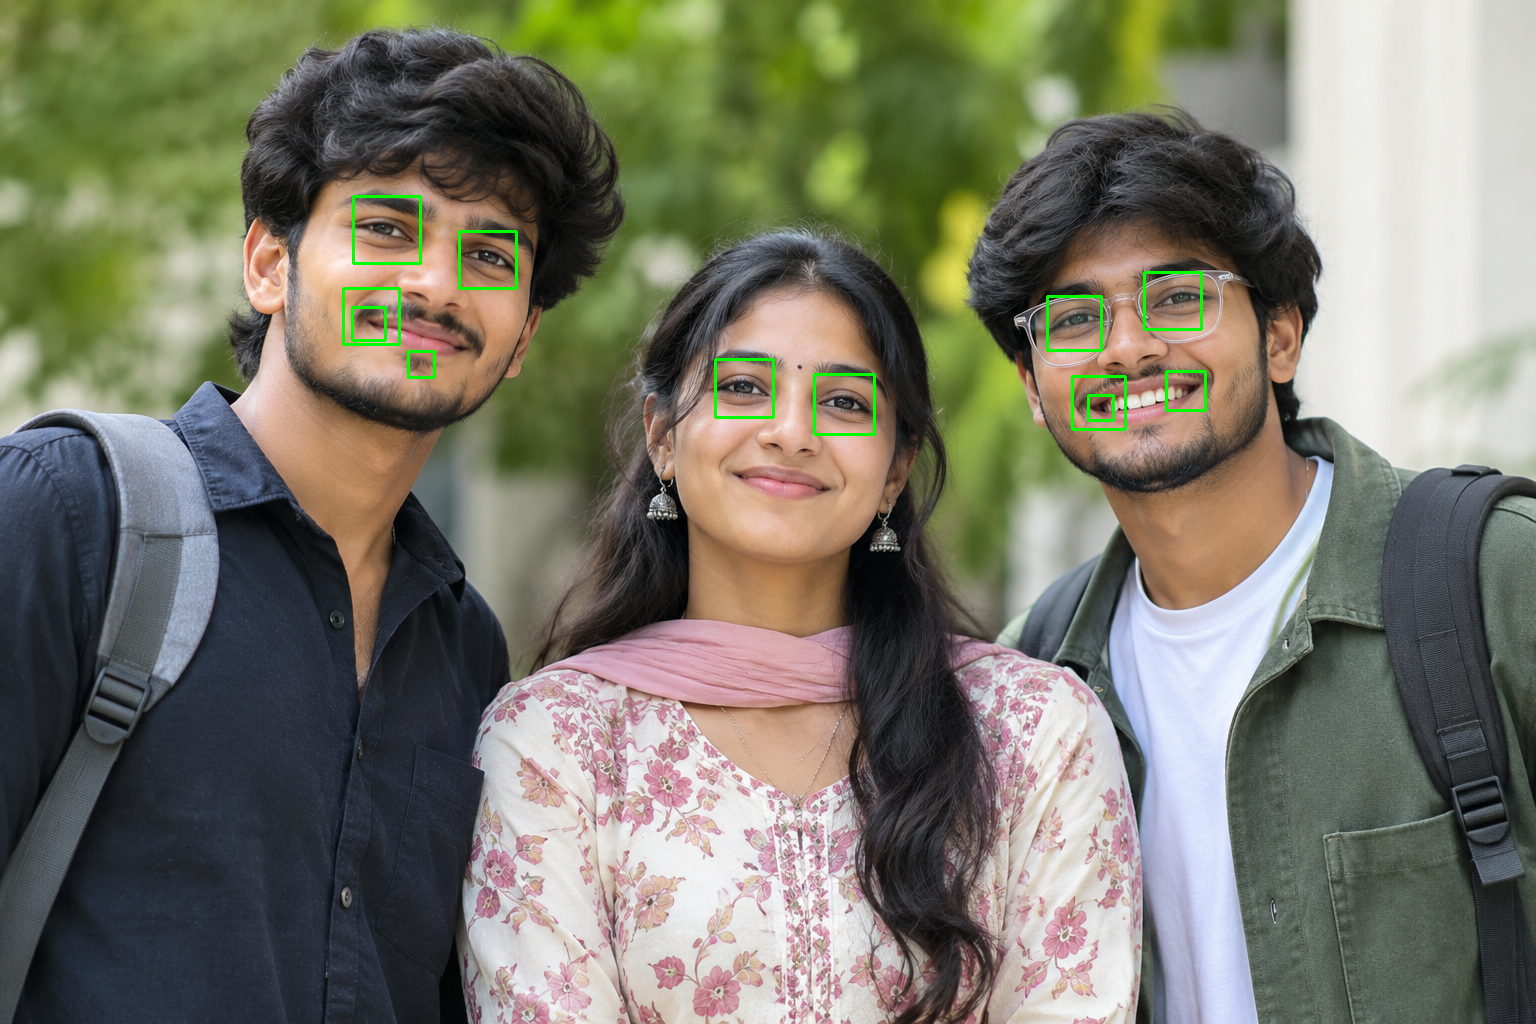

In [3]:

import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload image
uploaded = files.upload()

# Read uploaded image
filename = next(iter(uploaded))
img = cv2.imread(filename)

if img is None:
    print("Image not found")
else:
    # Convert image to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Load face and eye detection classifiers
    face_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades +
        "haarcascade_frontalface_default.xml"
    )

    eye_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades +
        "haarcascade_eye.xml"
    )

    # Detect faces
    faces = face_cascade.detectMultiScale(
        gray, 1.1, 5
    )

    eye_count = 0

    # Detect eyes inside each face
    for (x, y, w, h) in faces:
        roi_gray = gray[y:y+h, x:x+w]
        roi_color = img[y:y+h, x:x+w]

        eyes = eye_cascade.detectMultiScale(
            roi_gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(15, 15)
        )

        # Draw rectangles around eyes
        for (ex, ey, ew, eh) in eyes:
            cv2.rectangle(
                roi_color,
                (ex, ey),
                (ex+ew, ey+eh),
                (0, 255, 0),
                2
            )
            eye_count += 1

    # Display output
    print("Number of Faces:", len(faces))
    print("Number of Eyes Detected:", eye_count)
    print("Eye Detection Output")
    cv2_imshow(img)
